<a href="https://colab.research.google.com/github/CS-foreach/csforeach-wildlife-cda/blob/main/WildLifeData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Connect google colab to drive to make file loading easier
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Importing libraries, pandas for data processing, matplotlib for visualization
import pandas as pd
import matplotlib.pyplot as plt

#Get actual data from drive
file_path = '/content/drive/MyDrive/WildLifeData/observations-spiders.csv'

#Read data into dataframe, dataframes are temporary instances of databases
df = pd.read_csv(file_path)

In [ ]:
#Look at first five rows of data
print(df.head())

  observed_on           time_observed_at   latitude   longitude  \
0  2009-03-08  2009-03-08 06:00:00 -0400  33.124763 -116.667076   
1  2009-03-21  2009-03-21 11:01:00 -0400  32.836044 -117.046150   
2  2008-04-20  2008-04-20 11:13:00 -0400  32.840694 -117.039993   
3  2010-03-26                        NaN  33.329243 -116.400940   
4  2011-11-11                        NaN  32.840677 -117.258793   

          scientific_name  
0  Protolophus singularis  
1  Protolophus singularis  
2  Protolophus singularis  
3               Mecaphesa  
4    Neomolgus littoralis  


In [ ]:
#Look at dataframe dimensions, rows x columns
print(df.shape)

#Print what columns are in the dataframe
print(df.columns)

(38528, 5)
Index(['observed_on', 'time_observed_at', 'latitude', 'longitude',
       'scientific_name'],
      dtype='object')


In [ ]:
#identify datatype of each column
for column, dtype in df.dtypes.items():
    print(f"{column}: {dtype}")

observed_on: object
time_observed_at: object
latitude: float64
longitude: float64
scientific_name: object


In [ ]:
#Count how many null, none, or missing values there are
for column in df.columns:
    count = df[column].isna().sum()
    if count > 0:
        print(f"{column}: {count} null, none, or missing values")

time_observed_at: 434 null, none, or missing values


In [ ]:
#See if any rows are dropped because of null
before = len(df)
df_clean = df.dropna() #Don't change original df, drop null, none, or missing values
dropped = before - len(df_clean)

print(f"Dropped {dropped} rows; {len(df_clean)} rows remain.")

Dropped 434 rows; 38094 rows remain.


In [ ]:
#Make sure all latitude and longitude data are valid
invalid_coordinates = df[
    (~df["latitude"].between(-90, 90)) #~ is the not operator for dataframes
    | (~df["longitude"].between(-180, 180)) # | is an or statement for dictionaries
]

print(f"Rows with invalid coordinates: {len(invalid_coordinates)}")
print(invalid_coordinates)

Rows with invalid coordinates: 0
Empty DataFrame
Columns: [observed_on, time_observed_at, latitude, longitude, scientific_name]
Index: []


In [ ]:
#Check for duplicate rows of data, only when all column values are equal
duplicate_columns = [
    "observed_on",
    "time_observed_at",
    "latitude",
    "longitude",
    "scientific_name",
]

#Remove duplicate rows of data
df_clean = df_clean.drop_duplicates(subset=duplicate_columns, keep="first").copy()

print(f"Removed {len(df) - len(df_clean)} duplicate rows")

Removed 577 duplicate rows


In [ ]:
#This column was already standardized, but here is an example of what to do to standardize a string column

#Make sure all values are strings in this column
names = df_clean["scientific_name"].astype("string")

#Get rid of spaces before and after string
stripped = names.str.strip()
#Get rid of extra spaces in center
spacing_normalized = stripped.str.replace(r"\s+", " ", regex=True)

#Rows affected by strip()
strip_changed = names.notna() & names.ne(stripped)

print("Changed by strip():")
print(df_clean.loc[strip_changed, ["scientific_name"]].assign(after_strip=stripped[strip_changed]))

#Rows affected by replace()
replace_changed = stripped.notna() & stripped.ne(spacing_normalized)

print("\nChanged by replace():")
print(
    df_clean.loc[replace_changed, ["scientific_name"]]
    .assign(after_strip=stripped[replace_changed],
            after_replace=spacing_normalized[replace_changed])
)


Changed by strip():
Empty DataFrame
Columns: [scientific_name, after_strip]
Index: []

Changed by replace():
Empty DataFrame
Columns: [scientific_name, after_strip, after_replace]
Index: []


In [ ]:
print(df_clean.head)

<bound method NDFrame.head of       observed_on           time_observed_at   latitude   longitude  \
0      2009-03-08  2009-03-08 06:00:00 -0400  33.124763 -116.667076   
1      2009-03-21  2009-03-21 11:01:00 -0400  32.836044 -117.046150   
2      2008-04-20  2008-04-20 11:13:00 -0400  32.840694 -117.039993   
15     2013-01-30  2013-01-30 23:06:48 -0500  32.849674 -116.996478   
16     2013-02-04  2013-02-04 13:38:22 -0500  32.892710 -117.242730   
...           ...                        ...        ...         ...   
38523  2026-11-03  2026-11-03 22:35:09 -0500  32.803473 -117.053496   
38524  2026-11-03  2026-11-04 00:17:44 -0500  33.222445 -116.390307   
38525  2026-11-03  2026-11-04 01:21:36 -0500  32.902159 -117.087280   
38526  2026-11-03  2026-11-03 11:47:27 -0500  33.220608 -117.297378   
38527  2026-11-04  2026-11-04 10:11:33 -0500  32.737478 -117.158840   

               scientific_name  
0       Protolophus singularis  
1       Protolophus singularis  
2       Protolophu

In [ ]:
#Filter dataframe to two different species using scientific name
species = ["Latrodectus geometricus", "Latrodectus hesperus"]
#Latrodectus geometricus, Brown Widow Spider = invasive,
#Latrodectus hesperus, Western Black Widow = native

final_df = df_clean[df_clean["scientific_name"].isin(species)].copy()

In [ ]:
print(final_df.head)

<bound method NDFrame.head of       observed_on           time_observed_at   latitude   longitude  \
15     2013-01-30  2013-01-30 23:06:48 -0500  32.849674 -116.996478   
28     2013-05-18  2013-05-18 23:30:22 -0400  32.849674 -116.996478   
38     2013-07-20  2013-07-20 13:36:02 -0400  32.558225 -117.092826   
41     2013-08-06  2013-08-06 17:58:08 -0400  32.849674 -116.996478   
44     2013-08-31  2013-08-31 14:23:13 -0400  32.935829 -116.481385   
...           ...                        ...        ...         ...   
38442  2026-10-26  2026-10-26 14:32:48 -0400  33.096806 -117.002189   
38462  2026-10-20  2026-10-20 12:59:23 -0400  32.741408 -117.252320   
38491  2026-11-01  2026-11-01 12:18:41 -0500  33.228005 -117.316055   
38505  2026-11-01  2026-11-02 00:37:08 -0500  32.820339 -117.182368   
38506  2026-11-02  2026-11-02 15:07:53 -0500  32.751730 -117.144469   

               scientific_name  
15     Latrodectus geometricus  
28        Latrodectus hesperus  
38        Latrodec

In [ ]:
#Get counts of both species
species_counts = final_df["scientific_name"].value_counts()
print(species_counts)

scientific_name
Latrodectus geometricus    2364
Latrodectus hesperus       1155
Name: count, dtype: int64


scientific_name
Latrodectus geometricus    2364
Latrodectus hesperus       1155
Name: count, dtype: int64


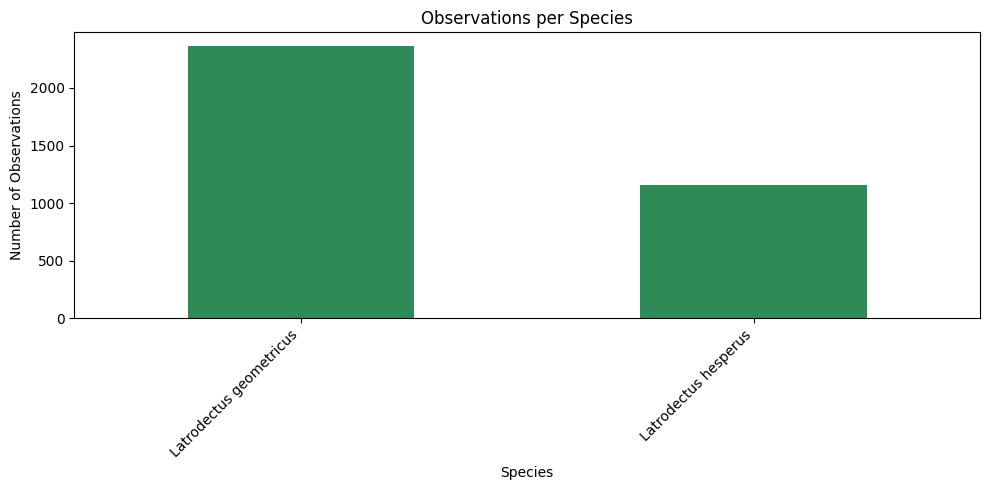

In [ ]:
#Create a graph of species counts for whatever reason
observations_per_species = (
    final_df["scientific_name"]
    .value_counts()
    .sort_values(ascending=False)
)

print(observations_per_species)

observations_per_species.plot(kind="bar", figsize=(10, 5), color="seagreen")
plt.title("Observations per Species")
plt.xlabel("Species")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#Parse dates such as "2013-01-30"
final_df["observed_on"] = pd.to_datetime(
    final_df["observed_on"],
    format="%Y-%m-%d",
    errors="coerce"
)

#Count observations per day
observations_per_day = (
    final_df.dropna(subset=["observed_on"])
    .groupby(final_df["observed_on"].dt.date)
    .size()
)

#Count observations per month, can use dt.to_period because of pd.to_datetime() before
observations_per_month = (
    final_df.groupby(final_df["observed_on"].dt.month).size()
)

#Count observations per year, , can use dt.year because of pd.to_datetime() before
observations_per_year = (
    final_df.groupby(final_df["observed_on"].dt.year).size()
)

#This really isn't that helpful
print("Observations per day:")
print(observations_per_day)

#These are more interesting and informative
print("\nObservations per month:")
print(observations_per_month)

print("\nObservations per year:")
print(observations_per_year)

Observations per day:
observed_on
1979-12-31    1
2005-04-10    1
2008-05-17    1
2008-05-19    1
2008-09-10    1
             ..
2026-10-25    1
2026-10-26    1
2026-10-27    1
2026-11-01    2
2026-11-02    1
Length: 1891, dtype: int64

Observations per month:
observed_on
1      99
2     152
3     192
4     249
5     212
6     249
7     383
8     556
9     683
10    404
11    218
12    122
dtype: int64

Observations per year:
observed_on
1979      1
2005      1
2008      4
2010      2
2012      3
2013     11
2014     38
2015     29
2016     69
2017    107
2018    175
2019    207
2020    301
2021    309
2022    470
2023    321
2024    320
2025    465
2026    686
dtype: int64


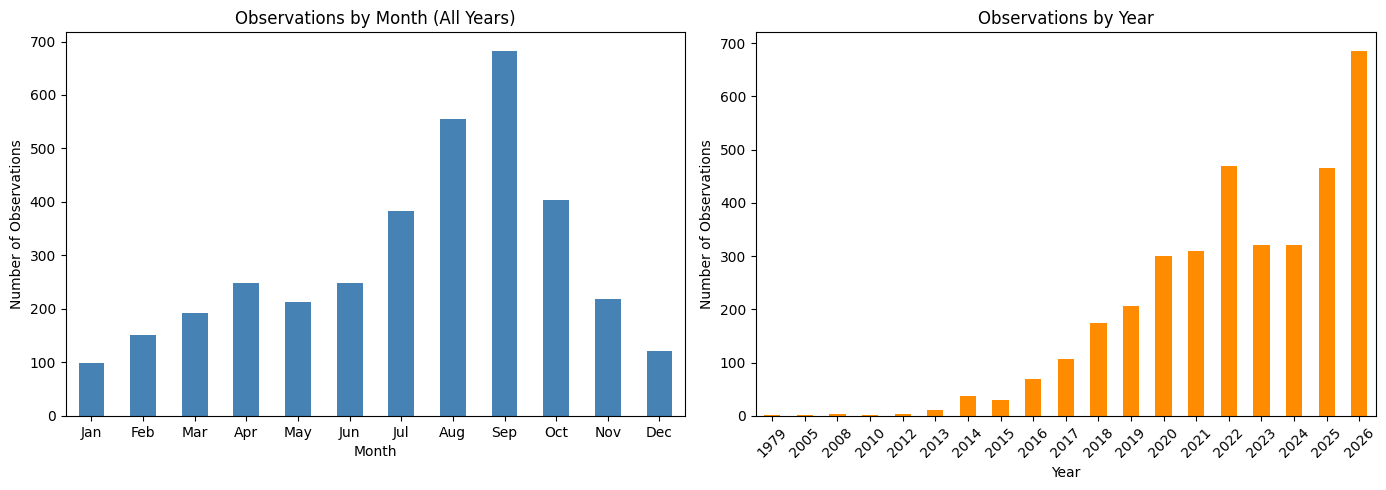

In [ ]:
#Look at total observations for both species per month and year
#Months can be from any of the years
#Plot both charts, create two charts next to each other and set size
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

observations_per_month.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Observations by Month (All Years)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Observations")
axes[0].set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)

observations_per_year.plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Observations by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Number of Observations")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#Count observations by species and month
species_by_month = (
    final_df.groupby([final_df["observed_on"].dt.month, "scientific_name"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
)

#Count observations by species and year
species_by_year = (
    final_df.groupby([final_df["observed_on"].dt.year, "scientific_name"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

#Make custom labels for graph legend
species_labels = {
    "Latrodectus hesperus": "Latrodectus hesperus (native)",
    "Latrodectus geometricus": "Latrodectus geometricus (invasive)",
}


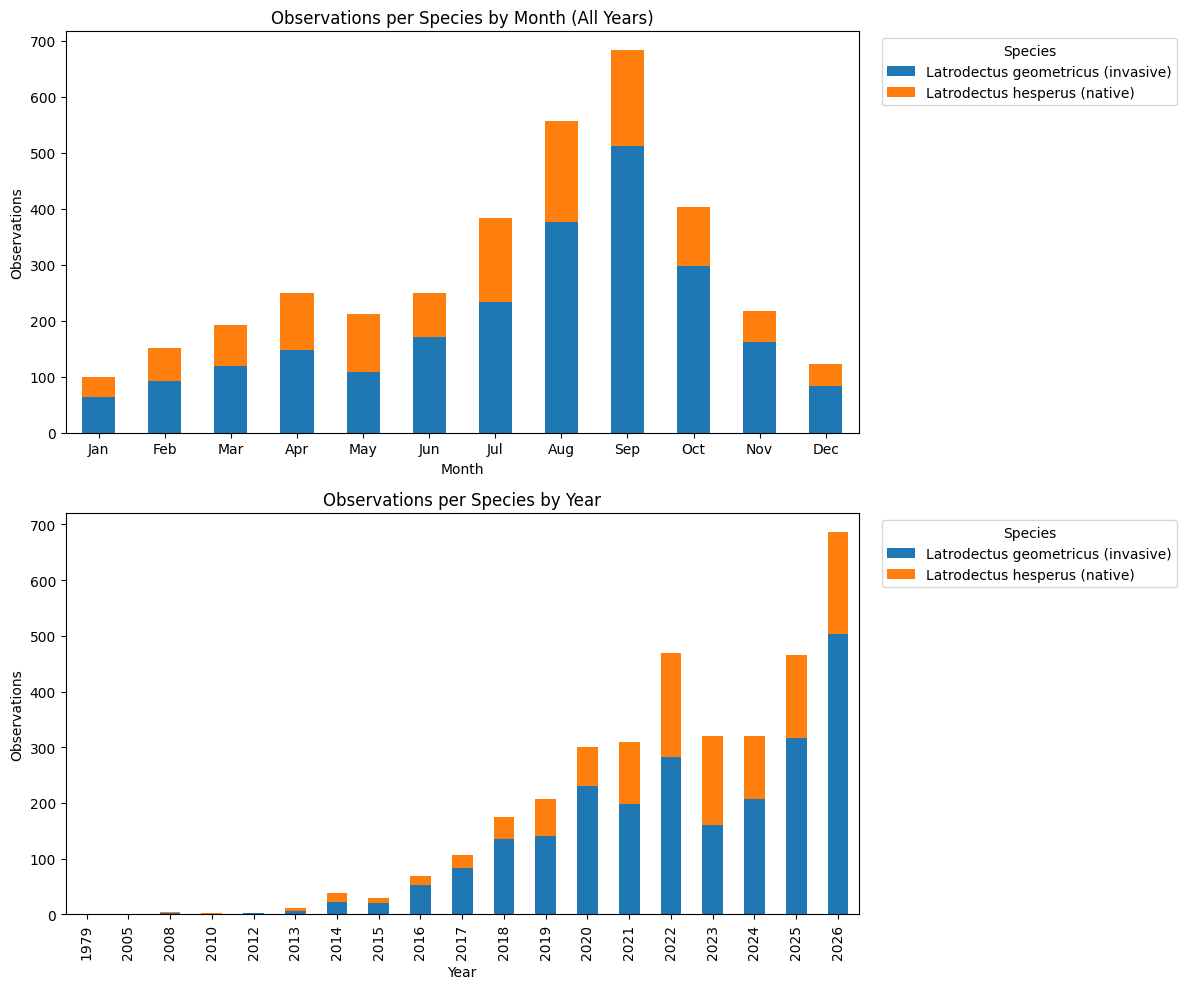

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

species_by_month.plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Observations per Species by Month (All Years)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Observations")
axes[0].set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)

species_by_year.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Observations per Species by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Observations")

#Edit legend to add invasive or native
for ax in axes:
    handles, labels = ax.get_legend_handles_labels()
    labels = [species_labels.get(name, name) for name in labels]
    ax.legend(handles, labels, title="Species", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [ ]:
!pip -q install folium
import folium
from IPython.display import display

In [ ]:
#Define species color for map markers
species_colors = {
    "Latrodectus geometricus": "red",   # Brown widow
    "Latrodectus hesperus": "blue",     # Western black widow
}

#Create new map with imported python library
mymap = folium.Map(
    location=[final_df["latitude"].mean(), final_df["longitude"].mean()], #Center near the average latitude and longitude coordinates
    zoom_start=11,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}", #Part of the library
    attr="Tiles © Esri"   #Credit
)

for _, row in final_df.iterrows():
    species = row["scientific_name"]
    #Assign marker based on species
    folium.Marker(
        location=[row["latitude"], row["longitude"]],
        popup=species,
        tooltip=species,
        icon=folium.Icon(color=species_colors[species], icon="info-sign")
    ).add_to(mymap)

display(mymap)